# 04 · Optimización: corridas, sensibilidad de hiperparámetros, sobreajuste, calibración y umbral

**Proyecto:** Copiloto de triaje para neumonía en adultos · Proyecto Integrador, Maestría en Inteligencia Artificial (UEES), 2026.
**Cuaderno 4 de 5** (`01_exploracion` · `02_preprocesamiento` · `03_modelado` · `04_optimizacion` · `05_evaluacion`).

## Qué hace este cuaderno, y qué no promete

Cuenta **cómo se llegó a la configuración final** del modelo con lo que de verdad se midió: las corridas de entrenamiento que quedaron guardadas, sus historiales por época y los datos de validación. Tiene seis partes:

1. el objetivo y el punto de partida;
2. la **comparación de las corridas** (arquitecturas, 320 px, lote, épocas, fases de ajuste fino) con las funciones de `scripts/comparar_corridas.py`;
3. el **análisis de sensibilidad de hiperparámetros**, construido **solo con esas corridas reales**;
4. el **diagnóstico de sobreajuste y subajuste** (con `scripts/diagnostico_curvas.py`);
5. la **calibración** y la **elección del umbral de cribado** (con las funciones del paquete, sobre las puntuaciones de validación recalculadas aquí);
6. el **umbral por vista**.

**Una advertencia que condiciona todo lo demás.** Las corridas no se diseñaron como un barrido: casi todo lo que cambió entre la primera corrida y la final cambió a la vez, y las ocho corridas que quedan comparten 320 px, lote 24, el mismo planificador y la misma paciencia, y siete de ellas el mismo esquema de 4 + 20 épocas. Lo que sí varía entre ellas es la **arquitectura**, el número de **épocas de ajuste** (en una sola corrida) y, dentro de cada configuración, la **repetición**. Por eso este cuaderno **no puede** dar curvas de dependencia parcial, un ranking de importancia de hiperparámetros ni interacciones, y lo dice en cada sitio donde el dato no alcanza. Lo que sí hace es medir cuánto se mueve el resultado entre repeticiones de la misma configuración (el ruido) y comparar contra él cada efecto que se observa.

## Cómo ejecutarlo

Necesita el conjunto preparado (`RSNA_RAIZ`, con `corridas/`, `png/` y `manifiestos/`; ver `data/README.md`) y los pesos del modelo desplegado, que se localizan y se **verifican por su SHA-256**. La parte de calibración y umbral recalcula las puntuaciones de las 3 810 radiografías de validación en CPU: tarda unos minutos.

In [1]:
import hashlib
import json
import re
import sys
import tempfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as MostrarImagen, display
from sklearn.metrics import roc_auc_score, roc_curve

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def raiz_del_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "pyproject.toml").is_file() and (carpeta / "src" / "copiloto_triaje").is_dir():
            return carpeta
    raise SystemExit("Abre el cuaderno dentro del repositorio: no se encontró pyproject.toml.")


REPO = raiz_del_repositorio()
for carpeta in ("src", "scripts", "app"):
    sys.path.insert(0, str(REPO / carpeta))

import comparar_corridas as cc        # noqa: E402  scripts/comparar_corridas.py
import diagnostico_curvas as dx       # noqa: E402  scripts/diagnostico_curvas.py
from copiloto_triaje.config import Config, raiz_rsna  # noqa: E402

RAIZ = raiz_rsna()
assert (RAIZ / "corridas").is_dir() and (RAIZ / "manifiestos").is_dir(), "RSNA_RAIZ no apunta a un conjunto preparado"
METRICAS = json.loads((REPO / "app" / "assets" / "metricas.json").read_text(encoding="utf-8"))
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| torch", torch.__version__)

# Un color por arquitectura, el mismo en todas las figuras (paleta de Okabe-Ito, legible con daltonismo).
ARQUITECTURAS = {"efficientnet_b0": ("EffNet-B0", "#0072B2"),
                 "densenet121": ("DenseNet121", "#D55E00"),
                 "mobilenet_v3_large": ("MobileNetV3-L", "#009E73")}

Python 3.13.16 | numpy 2.5.2 | pandas 3.0.5 | torch 2.14.0+cpu


## 1. El objetivo y las restricciones

**Qué se optimiza.** El proyecto es un **cribado**: en triaje, el falso negativo (mandar a casa una neumonía) es el error caro, así que la métrica primaria es el **recall** y se exige una especificidad mínima para que el cribado no sature al profesional. Los criterios de aceptación salen del spec §2 y viven en `copiloto_triaje.modelo.reporte.CRITERIOS_ACEPTACION`; el umbral de decisión se elige sobre validación con `elegir_umbral`.

**Restricción de sistema.** La inferencia debe servirse en la CPU del servidor en menos de 4 s por imagen. La primera arquitectura (MobileNetV3-Large) se eligió por esa restricción; la medición real dio 0,023 s por imagen (el 0,6 % del presupuesto, `docs/mejoras-2026-09-21.md` §5), así que dejó de ser vinculante y se pudo usar una red más capaz.

In [2]:
from copiloto_triaje.modelo.reporte import CRITERIOS_ACEPTACION

criterios = pd.DataFrame(CRITERIOS_ACEPTACION, columns=["criterio", "clave", "mínimo", "objetivo"]).drop(columns="clave")
print("Criterios de aceptación (spec §2), sobre el conjunto de PRUEBA:")
print(criterios.to_string(index=False))

cfg = Config(raiz_datos=RAIZ, zip_rsna=RAIZ)
print("\nLo que Config deja ajustar (valores por defecto) y no está en el bloque `corrida` de los reportes:")
print(f"  tasa de aprendizaje: cabeza {cfg.lr_cabeza}, ajuste fino {cfg.lr_ajuste} (optimizador Adam)")
print(f"  semilla: {cfg.semilla} | proporciones de la partición: {cfg.proporciones}")

Criterios de aceptación (spec §2), sobre el conjunto de PRUEBA:
             criterio  mínimo  objetivo
Recall (sensibilidad)    0.80      0.85
        Especificidad    0.70      0.75
              AUC-ROC    0.85      0.88

Lo que Config deja ajustar (valores por defecto) y no está en el bloque `corrida` de los reportes:
  tasa de aprendizaje: cabeza 0.001, ajuste fino 0.0002 (optimizador Adam)
  semilla: 42 | proporciones de la partición: (0.7, 0.15, 0.15)


## 2. De dónde se partió y qué se cambió

La **primera corrida** (19-sep-2026) no está en disco: lo que se conserva es su descripción y sus cifras en `docs/mejoras-2026-09-21.md` §1, y de ahí salen las que siguen. Se entrenó con MobileNetV3-Large a 224 px, lote 32, ajuste fino de los 3 últimos bloques, tasa fija y paciencia 3; paró por paciencia a las 7 épocas con el AUC de validación todavía subiendo.

Entre esa corrida y la final se cambiaron **ocho cosas a la vez** (`docs/mejoras-2026-09-21.md` §4):

| Cambio | De | A |
| :--- | :--- | :--- |
| Resolución | 224 px | **320 px** |
| Arquitectura | MobileNetV3-Large | DenseNet121, y luego **EfficientNet-B0** (§3) |
| Épocas | 3 + 7 previstas (paró en la 7) | **4 + 20** |
| Ajuste fino | 3 últimos bloques | **red completa** |
| Tasa de aprendizaje | fija | **recocido coseno** |
| Paciencia | 3 | **5** |
| Lote | 32 | **24** |
| Población | todo el padrón | **solo adultos (18-100 años)** |

Además se **corrigió la regla del umbral** (`elegir_umbral`): la versión original conservaba un punto que incumplía el recall mínimo teniendo otro que cumplía los dos mínimos. Según ese documento, esa corrección sola habría llevado el recall de la primera corrida de 76,6 % a unos 83 %, sin reentrenar.

**Consecuencia para este cuaderno:** el cambio de 224 a 320 px, el de arquitectura, el de épocas, etc., **no se pueden separar**: se hicieron juntos y la primera corrida no se repitió cambiando una sola cosa. Lo que sigue es una comparación **antes / después del conjunto**, no una atribución por hiperparámetro.

In [3]:
g = METRICAS["global"]
antes = {"recall": 0.766, "especificidad": 0.764, "auc": 0.845}      # docs/mejoras-2026-09-21.md §1, prueba
despues = {"recall": g["recall"], "especificidad": g["especificidad"], "auc": g["auc"]}  # app/assets/metricas.json, prueba
filas = []
for nombre, clave, minimo, objetivo in CRITERIOS_ACEPTACION:
    def veredicto(v):
        return "objetivo" if v >= objetivo else ("mínimo" if v >= minimo else "NO cumple")
    filas.append({"criterio": nombre, "mínimo": minimo, "objetivo": objetivo,
                  "1.ª corrida": antes[clave], "cumple (1.ª)": veredicto(antes[clave]),
                  "corrida final": round(despues[clave], 4), "cumple (final)": veredicto(despues[clave])})
print("Antes y después, sobre el conjunto de PRUEBA (las dos son una sola corrida cada una):")
print(pd.DataFrame(filas).to_string(index=False))
print("\nLa 1.ª corrida es la de docs/mejoras-2026-09-21.md §1; la final, la de app/assets/metricas.json (umbral 0,4258).")
print("Cuidado al comparar: la población cambió (filtro de edad) y la regla del umbral también.")

Antes y después, sobre el conjunto de PRUEBA (las dos son una sola corrida cada una):
             criterio  mínimo  objetivo  1.ª corrida cumple (1.ª)  corrida final cumple (final)
Recall (sensibilidad)    0.80      0.85        0.766    NO cumple         0.8815       objetivo
        Especificidad    0.70      0.75        0.764     objetivo         0.7024         mínimo
              AUC-ROC    0.85      0.88        0.845    NO cumple         0.8848       objetivo

La 1.ª corrida es la de docs/mejoras-2026-09-21.md §1; la final, la de app/assets/metricas.json (umbral 0,4258).
Cuidado al comparar: la población cambió (filtro de edad) y la regla del umbral también.


## 3. Las corridas, comparadas

Quedan **ocho corridas** guardadas. Se leen con las funciones de `scripts/comparar_corridas.py` (las mismas que generaron `docs/comparativa-corridas.md`), que aplican la regla de selección del proyecto: primero cuántos de los tres criterios del spec cumple cada una en prueba, luego el recall, luego el AUC.

In [4]:
carpetas = sorted(p for p in (RAIZ / "corridas").iterdir() if p.is_dir())
reportes, resumenes = {}, []
for carpeta in carpetas:
    reporte, ruta_json = cc.cargar_reporte(carpeta)
    resumen = cc.resumir(reporte, ruta_json)
    reportes[resumen["nombre"]] = reporte
    resumenes.append(resumen)

ordenadas = cc.ordenar_corridas(resumenes)
ganadora, paso = cc.elegir_ganadora(resumenes)
print(f"{len(resumenes)} corridas leídas. Gana por la regla del proyecto: {ganadora['nombre']}  (regla: {paso})")

DESPLEGADA = "efficientnet_b0_320px_lote24_4+20ep"
assert DESPLEGADA in reportes


def etiqueta_corta(nombre, arquitectura):
    nombre_arq = ARQUITECTURAS[arquitectura][0]
    if nombre == DESPLEGADA:
        return f"{nombre_arq} · corrida 6 (desplegada)"
    if nombre.startswith("kaggle_"):
        return f"{nombre_arq} · Kaggle {nombre.rsplit('_', 1)[1]}"
    return f"{nombre_arq} · Colab 4+4"


def en_epoca(reporte, epoca):
    return next(e for e in reporte["historial"] if e["epoca"] == epoca)


tabla = []
for puesto, r in enumerate(ordenadas, 1):
    rep = reportes[r["nombre"]]
    c, p = r["corrida"], r["prueba"]
    h = rep["historial"]
    elegida = en_epoca(rep, r["mejor_epoca"])
    tabla.append({
        "puesto": puesto, "corrida": etiqueta_corta(r["nombre"], c["arquitectura"]),
        "épocas": "+".join(map(str, c["epocas"])), "mejor época": r["mejor_epoca"], "épocas corridas": len(h),
        "AUC val.": round(elegida["auc"], 4), "AUC prueba": round(p["auc"], 4),
        "recall prueba": round(p["recall"], 4), "espec. prueba": round(p["especificidad"], 4),
        "criterios": f"{r['criterios_cumplidos']}/3", "segundos": c.get("segundos_entrenamiento"),
        "arq": c["arquitectura"], "nombre": r["nombre"], "reconstruida": bool(c.get("reconstruido_de_consola"))})
tabla = pd.DataFrame(tabla)
print(tabla.drop(columns=["arq", "nombre", "reconstruida"]).to_string(index=False))

# ¿es el orden el que publica docs/comparativa-corridas.md?
ruta_doc = REPO / "docs" / "comparativa-corridas.md"
if ruta_doc.is_file():
    en_doc = re.findall(r"^\| \d+ \| `([^`]+)` \|", ruta_doc.read_text(encoding="utf-8"), flags=re.M)
    print("\nel orden coincide con docs/comparativa-corridas.md:", en_doc == [r["nombre"] for r in ordenadas])

# La misma comparación por VALIDACIÓN (la que no gasta la prueba) en la época elegida:
por_val = tabla.sort_values("AUC val.", ascending=False).reset_index(drop=True)
puesto_desplegada = int(por_val.index[por_val["nombre"] == DESPLEGADA][0]) + 1
mejor_val = por_val.loc[0]
print(f"\nPor AUC de validación en la época elegida, la desplegada es la {puesto_desplegada}.ª de {len(por_val)}, "
      f"a {mejor_val['AUC val.'] - por_val.loc[puesto_desplegada - 1, 'AUC val.']:.4f} de AUC de la primera "
      f"({mejor_val['corrida']}).")

8 corridas leídas. Gana por la regla del proyecto: kaggle_efficientnet_b0_320px_c2  (regla: paso_2_mayor_recall)
 puesto                            corrida épocas  mejor época  épocas corridas  AUC val.  AUC prueba  recall prueba  espec. prueba criterios  segundos
      1              EffNet-B0 · Kaggle c2   4+20            6               12    0.8850      0.8892         0.8922         0.7088       3/3    1723.9
      2            DenseNet121 · Kaggle c1   4+20           10               16    0.8790      0.8740         0.8910         0.7020       3/3    5832.0
      3            DenseNet121 · Kaggle c2   4+20           10               16    0.8793      0.8744         0.8910         0.7024       3/3    5647.4
      4              EffNet-B0 · Kaggle c1   4+20            6               12    0.8840      0.8880         0.8890         0.7080       3/3    1800.0
      5          MobileNetV3-L · Kaggle c1   4+20            6               12    0.8790      0.8860         0.8820         0.

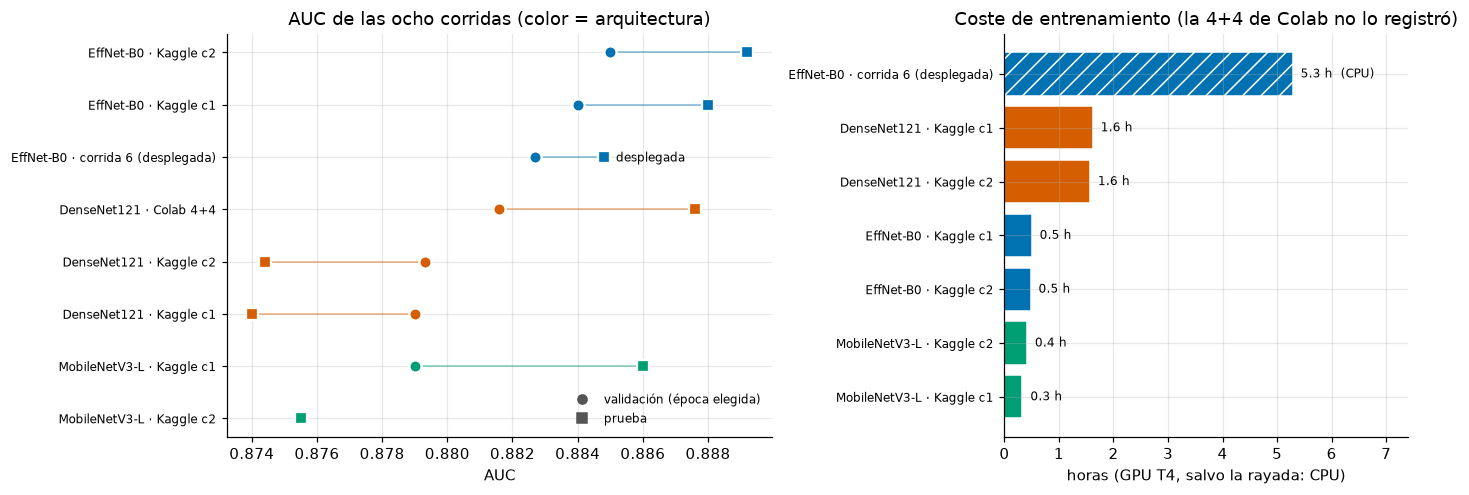

In [5]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})

orden_fig = por_val.iloc[::-1].reset_index(drop=True)  # la mejor por validación, arriba
for y, fila in orden_fig.iterrows():
    color = ARQUITECTURAS[fila["arq"]][1]
    izq.plot([fila["AUC val."], fila["AUC prueba"]], [y, y], color=color, lw=1, alpha=0.5)
    izq.plot(fila["AUC val."], y, "o", color=color, ms=8, mec="white", mew=1.5)
    izq.plot(fila["AUC prueba"], y, "s", color=color, ms=8, mec="white", mew=1.5)
    if fila["nombre"] == DESPLEGADA:
        izq.annotate("desplegada", (fila["AUC prueba"], y), xytext=(8, -3), textcoords="offset points", fontsize=8)
izq.set_yticks(range(len(orden_fig)), orden_fig["corrida"], fontsize=8)
izq.plot([], [], "o", color="#555555", label="validación (época elegida)")
izq.plot([], [], "s", color="#555555", label="prueba")
izq.legend(frameon=False, fontsize=8, loc="lower right")
izq.set(title="AUC de las ocho corridas (color = arquitectura)", xlabel="AUC")

con_tiempo = tabla.dropna(subset=["segundos"]).sort_values("segundos")
for y, (_, fila) in enumerate(con_tiempo.iterrows()):
    cpu = fila["nombre"] == DESPLEGADA
    der.barh(y, fila["segundos"] / 3600, color=ARQUITECTURAS[fila["arq"]][1], hatch="//" if cpu else None,
             edgecolor="white")
    der.text(fila["segundos"] / 3600, y, f"  {fila['segundos'] / 3600:.1f} h" + ("  (CPU)" if cpu else ""),
             va="center", fontsize=8)
der.set_yticks(range(len(con_tiempo)), con_tiempo["corrida"], fontsize=8)
der.set(title="Coste de entrenamiento (la 4+4 de Colab no lo registró)", xlabel="horas (GPU T4, salvo la rayada: CPU)", xlim=(0, 7.4))
fig.tight_layout()
plt.show()

**Lectura.**

- **Siete de las ocho cumplen los tres mínimos** del spec; la octava, DenseNet121 con 4+4 épocas (Colab), se queda en 0,699 de especificidad, una milésima por debajo del mínimo. El rango completo de AUC en prueba es de unas **0,015** entre la mejor y la peor.
- La regla de selección corona a `kaggle_efficientnet_b0_320px_c2`, y **no es la que está desplegada**. La desplegada es la **corrida 6** (`efficientnet_b0_320px_lote24_4+20ep`, entrenada en CPU). `docs/sp2-despliegue.md` deja la razón escrita: las diferencias entre las ocho caben en lo que mueve el ruido de una repetición (ver §4.2), de modo que elegir la que queda arriba sería **seleccionar por ruido**; y la corrida 6 es la que tiene el **calibrador ajustado sobre su propia validación** y los **pesos verificados por SHA-256**. Cambiar de corrida obliga a reajustar el calibrador, volver a medir la frontera y reelegir el umbral.
- Hay una segunda reserva que el propio informe de la comparativa escribe: elegir entre varias corridas mirando la **prueba** es usar la prueba para seleccionar, y deja la cifra de la ganadora algo optimista. Por eso la tabla de arriba incluye también la validación.
- El coste importa: EfficientNet-B0 y MobileNetV3 se entrenan en una fracción del tiempo de DenseNet121 en la misma GPU.

## 4. Análisis de sensibilidad de hiperparámetros

### 4.1 Qué varía entre las ocho corridas y qué no

Cada reporte guarda el bloque `corrida` con su configuración. Lo primero es mirar **qué hiperparámetros toman más de un valor**: solo de esos se puede decir algo.

In [6]:
def texto_valor(v):
    if isinstance(v, list):
        return "+".join(map(str, v)) if len(v) == 2 and v != [18, 100] else "-".join(map(str, v))
    return "sí" if v is True else ("no" if v is False else str(v))


CAMPOS = [("arquitectura", "arquitectura"), ("tam_imagen", "resolución (px)"), ("lote", "tamaño de lote"),
          ("epocas", "épocas (cabeza+ajuste)"), ("ajuste_fino_completo", "ajuste fino de toda la red"),
          ("scheduler_coseno", "planificador coseno"), ("paciencia", "paciencia (por fase)"),
          ("edad", "rango de edad")]
filas = []
for clave, etiqueta in CAMPOS:
    valores = Counter(texto_valor(r["corrida"].get(clave)) for r in resumenes)
    filas.append({"hiperparámetro": etiqueta, "valores (nº de corridas)": ", ".join(f"{v} ({n})" for v, n in valores.items()),
                  "¿varía?": "SÍ" if len(valores) > 1 else "no"})
print(pd.DataFrame(filas).to_string(index=False))
print("\nNo están en el reporte (valen lo que fija Config): tasa de aprendizaje, optimizador, aumento de datos y semilla.")
print("Plataforma y dispositivo también cambian (CPU / GPU T4, Colab / Kaggle), pero no son hiperparámetros.")

            hiperparámetro                                     valores (nº de corridas) ¿varía?
              arquitectura densenet121 (3), efficientnet_b0 (3), mobilenet_v3_large (2)      SÍ
           resolución (px)                                                      320 (8)      no
            tamaño de lote                                                       24 (8)      no
    épocas (cabeza+ajuste)                                            4+4 (1), 4+20 (7)      SÍ
ajuste fino de toda la red                                                       sí (8)      no
       planificador coseno                                                       sí (8)      no
      paciencia (por fase)                                                        5 (8)      no
             rango de edad                                                   18-100 (8)      no

No están en el reporte (valen lo que fija Config): tasa de aprendizaje, optimizador, aumento de datos y semilla.
Plataforma y dispositi

Solo varían la **arquitectura** (tres valores) y las **épocas** (4+4 en una corrida, 4+20 en las demás). **Resolución, lote, ajuste fino completo, planificador, paciencia y rango de edad valen lo mismo en las ocho**: con estas corridas **no se puede decir nada** de la sensibilidad a ellos. Tampoco de la tasa de aprendizaje, el optimizador, el aumento o la semilla, que ni siquiera se registran.

### 4.2 El suelo de ruido: cuánto se mueve el resultado entre repeticiones de la misma configuración

Antes de atribuir una diferencia a un hiperparámetro hay que saber cuánto se mueve el resultado **sin cambiar nada**. Hay repeticiones de la misma configuración (arquitectura, 320 px, 4+20): EfficientNet-B0 tiene tres (la corrida 6 y dos de Kaggle), DenseNet121 y MobileNetV3-L, dos cada una. El reporte **no registra la semilla** (el valor por defecto de `Config` es 42), así que lo que miden estas repeticiones es la repetibilidad del entrenamiento tal como se hizo; con semillas distintas el ruido sería, si acaso, mayor.

In [7]:
base = tabla[tabla["épocas"] == "4+20"].copy()
base["AUC val."] = base["AUC val."].astype(float)
métricas = {"AUC val.": "AUC val.", "AUC prueba": "AUC prueba", "recall prueba": "recall prueba", "espec. prueba": "espec. prueba"}

resumen_ruido = []
for arq, grupo in base.groupby("arq"):
    fila = {"arquitectura": ARQUITECTURAS[arq][0], "repeticiones": len(grupo)}
    for etiqueta, columna in métricas.items():
        fila[f"{etiqueta}: media"] = round(grupo[columna].mean(), 4)
        fila[f"{etiqueta}: rango"] = round(grupo[columna].max() - grupo[columna].min(), 4)
    resumen_ruido.append(fila)
resumen_ruido = pd.DataFrame(resumen_ruido)
print("Corridas 4+20 (siete), por arquitectura. 'rango' = máximo menos mínimo entre repeticiones de la MISMA configuración:")
print(resumen_ruido.to_string(index=False))

ruido = {c: resumen_ruido[f"{c}: rango"].max() for c in métricas}
print("\nSuelo de ruido (el mayor rango entre repeticiones):",
      {c: round(v, 4) for c, v in ruido.items()})

# Las dos corridas de DenseNet121 (c1, c2): ¿son realmente dos muestras?
c1 = reportes["kaggle_densenet121_320px_c1"]["historial"]
c2 = reportes["kaggle_densenet121_320px_c2"]["historial"]
iguales = sum(round(x["auc"], 3) == round(y["auc"], 3) and round(x["perdida"], 3) == round(y["perdida"], 3)
              for x, y in zip(c1, c2))
print(f"\nDenseNet121 c1 y c2: coinciden en {iguales} de {len(c1)} épocas (AUC y pérdida, a 3 decimales).")

Corridas 4+20 (siete), por arquitectura. 'rango' = máximo menos mínimo entre repeticiones de la MISMA configuración:
 arquitectura  repeticiones  AUC val.: media  AUC val.: rango  AUC prueba: media  AUC prueba: rango  recall prueba: media  recall prueba: rango  espec. prueba: media  espec. prueba: rango
  DenseNet121             2           0.8792           0.0003             0.8742             0.0004                0.8910                0.0000                0.7022                0.0004
    EffNet-B0             3           0.8839           0.0023             0.8873             0.0044                0.8876                0.0107                0.7064                0.0064
MobileNetV3-L             2           0.8772           0.0035             0.8808             0.0105                0.8782                0.0076                0.7060                0.0001

Suelo de ruido (el mayor rango entre repeticiones): {'AUC val.': np.float64(0.0035), 'AUC prueba': np.float64(0.0105), 'recall pru

**Lectura.** Entre repeticiones de **la misma configuración**, el AUC de prueba se mueve hasta unas 0,010 (MobileNetV3-L), el recall hasta 0,011 (EfficientNet-B0) y la especificidad hasta 0,006. Ese es el orden de magnitud que cualquier efecto debe superar para tomarse en serio. Son rangos de **dos o tres repeticiones**: una estimación del ruido muy frágil.

Un aviso sobre DenseNet121: sus dos repeticiones (c1 y c2) coinciden en todas las épocas a tres decimales. O son la misma ejecución recogida dos veces (c1 se reconstruyó de la consola, c2 del JSON) o dos ejecuciones deterministas; los reportes no permiten distinguirlo. Como muestra de ruido, DenseNet121 cuenta, por tanto, como **una sola** observación, y su rango de ruido no es fiable: el suelo de arriba lo marca MobileNetV3-L.

### 4.3 ¿Importa la arquitectura?

Es el único hiperparámetro con tres valores. Se compara lo que separa a las arquitecturas **contra el suelo de ruido** que acaba de medirse.

Diferencia entre la mejor y la peor arquitectura (de las medias) frente al suelo de ruido:
  AUC val.       separación entre medias 0.0067 | ruido 0.0035 | cociente 1.91
  AUC prueba     separación entre medias 0.0131 | ruido 0.0105 | cociente 1.25
  recall prueba  separación entre medias 0.0128 | ruido 0.0107 | cociente 1.20
  espec. prueba  separación entre medias 0.0042 | ruido 0.0064 | cociente 0.66


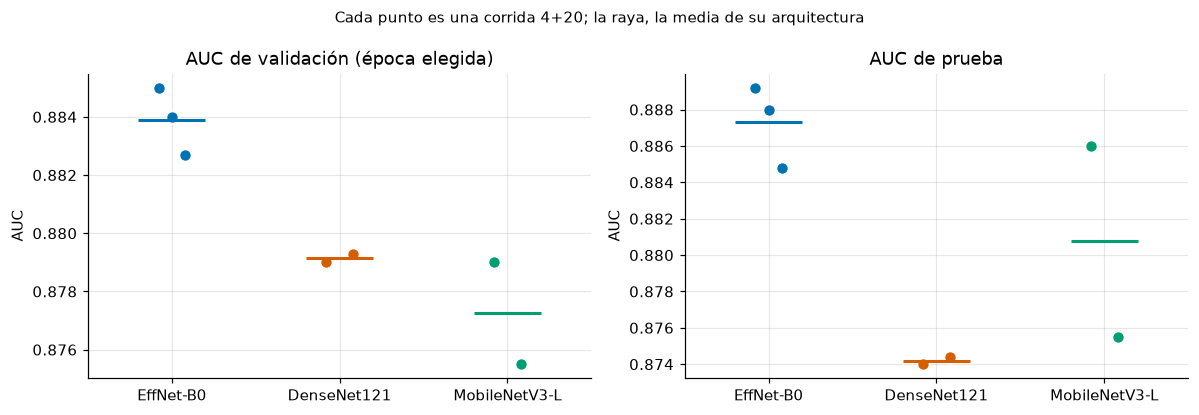

Tamaño del modelo exportado (checkpoints/pesos_modelo_cpu.pt), de las corridas que lo conservan:
  EffNet-B0 · corrida 6 (desplegada)      16.3 MB


  DenseNet121 · Kaggle c2                 28.4 MB
  EffNet-B0 · Kaggle c2                   16.3 MB


  MobileNetV3-L · Kaggle c2               17.0 MB


In [8]:
medias = resumen_ruido.set_index("arquitectura")
print("Diferencia entre la mejor y la peor arquitectura (de las medias) frente al suelo de ruido:")
for etiqueta in métricas:
    separacion = medias[f"{etiqueta}: media"].max() - medias[f"{etiqueta}: media"].min()
    print(f"  {etiqueta:<14} separación entre medias {separacion:.4f} | ruido {ruido[etiqueta]:.4f} | "
          f"cociente {separacion / ruido[etiqueta]:.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for eje, columna, titulo in zip(ejes, ("AUC val.", "AUC prueba"), ("AUC de validación (época elegida)", "AUC de prueba")):
    for x, (arq, (nombre_arq, color)) in enumerate(ARQUITECTURAS.items()):
        valores = base.loc[base["arq"] == arq, columna].to_numpy()
        desplazamiento = np.linspace(-0.08, 0.08, len(valores)) if len(valores) > 1 else [0]
        eje.plot(x + np.asarray(desplazamiento), valores, "o", color=color, ms=8, mec="white", mew=1.2)
        eje.hlines(valores.mean(), x - 0.2, x + 0.2, color=color, lw=2)
    eje.set_xticks(range(3), [v[0] for v in ARQUITECTURAS.values()])
    eje.set(title=titulo, ylabel="AUC", xlim=(-0.5, 2.5))
fig.suptitle("Cada punto es una corrida 4+20; la raya, la media de su arquitectura", fontsize=10)
fig.tight_layout()
plt.show()

print("Tamaño del modelo exportado (checkpoints/pesos_modelo_cpu.pt), de las corridas que lo conservan:")
for carpeta in carpetas:
    pesos = carpeta / "checkpoints" / "pesos_modelo_cpu.pt"
    if pesos.is_file():
        nombre = cc.cargar_reporte(carpeta)[0]["corrida"]["nombre"]
        arq = reportes[nombre]["corrida"]["arquitectura"]
        print(f"  {etiqueta_corta(nombre, arq):<38} {pesos.stat().st_size / 1e6:5.1f} MB")

**Lectura.** La separación entre arquitecturas es **de uno a dos ruidos**, no de muchos: el cociente es 1,9 en AUC de validación, 1,25 en AUC de prueba, 1,2 en recall y 0,7 en especificidad. Con dos o tres repeticiones por arquitectura (y las dos de DenseNet121 casi idénticas) eso **no basta para afirmar** que una arquitectura sea mejor que otra. Lo único consistente es que, **en validación**, las tres repeticiones de EfficientNet-B0 (0,8827 a 0,8850) quedan por encima de todas las de las otras dos arquitecturas (0,8755 a 0,8793); en prueba, los rangos se solapan (una de MobileNetV3-L supera a la corrida 6). La elección de EfficientNet-B0 se sostiene por **coste y tamaño** (entrena unas tres veces más rápido que DenseNet121 y su modelo pesa menos, ver arriba) y por un **rendimiento no peor**, no por una superioridad demostrada.

### 4.4 Épocas y fases del ajuste fino

Aquí caben tres observaciones, todas **dentro de las propias corridas**: qué aporta pasar de la fase de cabeza (backbone congelado) al ajuste fino, en qué época del ajuste se alcanza el mejor resultado, y el único contraste de épocas que hay (DenseNet121 con 4+4 frente a 4+20).

In [9]:
filas = []
for _, fila in tabla.iterrows():
    rep = reportes[fila["nombre"]]
    h = rep["historial"]
    cabeza = [e for e in h if e["fase"] == "cabeza"]
    ajuste = [e for e in h if e["fase"] == "ajuste"]
    elegida = en_epoca(rep, fila["mejor época"])
    n_cabeza = len(cabeza)
    filas.append({
        "corrida": fila["corrida"],
        "AUC val. fin de cabeza": round(cabeza[-1]["auc"], 4),
        "AUC val. ép.1 de cabeza": round(cabeza[0]["auc"], 4),
        "AUC val. mejor del ajuste": round(max(e["auc"] for e in ajuste), 4),
        "salto por descongelar": round(ajuste[0]["auc"] - cabeza[-1]["auc"], 4),
        "ajuste: épocas corridas": len(ajuste),
        "ajuste: nº de la elegida": elegida["epoca"] - n_cabeza + 1,
        "AUC val. última": round(h[-1]["auc"], 4),
        "AUC val. elegida": round(elegida["auc"], 4),
        "coste de no parar": round(h[-1]["auc"] - elegida["auc"], 4)})
fases = pd.DataFrame(filas)
print(fases.to_string(index=False))
print(f"\nCabeza: la mejora de la 1.ª a la última época de la fase es de {np.mean([f['AUC val. fin de cabeza'] - f['AUC val. ép.1 de cabeza'] for f in filas]):+.4f} de AUC de media.")
print(f"Descongelar el backbone: el AUC de validación sube {fases['salto por descongelar'].min():+.4f} a {fases['salto por descongelar'].max():+.4f} en la primera época del ajuste.")
print(f"Ninguna corrida 4+20 llegó al tope: el ajuste corrió de {fases[fases['corrida'].str.contains('Kaggle|desplegada')]['ajuste: épocas corridas'].min()} a "
      f"{fases[fases['corrida'].str.contains('Kaggle|desplegada')]['ajuste: épocas corridas'].max()} de las 20 previstas, y la época elegida fue la nº "
      f"{fases[fases['corrida'].str.contains('Kaggle|desplegada')]['ajuste: nº de la elegida'].min()} a la {fases[fases['corrida'].str.contains('Kaggle|desplegada')]['ajuste: nº de la elegida'].max()} del ajuste.")

                           corrida  AUC val. fin de cabeza  AUC val. ép.1 de cabeza  AUC val. mejor del ajuste  salto por descongelar  ajuste: épocas corridas  ajuste: nº de la elegida  AUC val. última  AUC val. elegida  coste de no parar
             EffNet-B0 · Kaggle c2                  0.8399                   0.8338                     0.8850                 0.0346                        8                         3           0.8708            0.8850            -0.0141
           DenseNet121 · Kaggle c1                  0.8260                   0.8180                     0.8790                 0.0450                       12                         7           0.8660            0.8790            -0.0130
           DenseNet121 · Kaggle c2                  0.8263                   0.8180                     0.8793                 0.0449                       12                         7           0.8664            0.8793            -0.0129
             EffNet-B0 · Kaggle c1          

**Lectura.**

- **Descongelar el backbone es, con diferencia, el mayor efecto que se observa** en estas corridas: la fase de cabeza mejora el AUC de validación apenas unas milésimas en sus cuatro épocas (+0,006 de media entre la primera y la última: ya iba plana), y en la primera época de ajuste fino sube de golpe entre 0,02 y 0,045, en las ocho corridas. Es un efecto claro frente al ruido (que es de milésimas), pero **no se puede atribuir solo a descongelar**: en ese punto cambian a la vez la tasa de aprendizaje (1e-3 en la cabeza, 2e-4 en el ajuste) y el conjunto de parámetros que se entrena. Lo que sí se puede decir es que seguir entrenando solo la cabeza no habría dado esa subida.
- **El tope de 20 épocas no ata nunca**: con paciencia 5 por fase, las corridas 4+20 se detienen mucho antes y la mejor época es una de las primeras del ajuste. Subir el tope no cambiaría nada; bajarlo por debajo de la época elegida (hasta la 7.ª del ajuste en DenseNet121) sí lo cambiaría.
- **Parar importa:** quedarse con la última época grabada en lugar de la elegida cuesta de 0,011 a 0,025 de AUC de validación en las siete corridas 4+20 (columna «coste de no parar», negativa = peor); en la 4+4 no cuesta nada porque la elegida es la última.

In [10]:
# El único contraste de épocas: DenseNet121 4+4 (Colab) frente a 4+20 (Kaggle c2).
cuatro_cuatro = tabla[tabla["épocas"] == "4+4"].iloc[0]
cuatro_veinte = tabla[tabla["nombre"] == "kaggle_densenet121_320px_c2"].iloc[0]
print("DenseNet121, 4+4 frente a 4+20 (c2):")
for etiqueta in ("AUC val.", "AUC prueba", "recall prueba", "espec. prueba"):
    print(f"  {etiqueta:<14} {cuatro_cuatro[etiqueta]:.4f} frente a {cuatro_veinte[etiqueta]:.4f}  "
          f"(diferencia {cuatro_cuatro[etiqueta] - cuatro_veinte[etiqueta]:+.4f}; ruido {ruido[etiqueta]:.4f})")
print(f"  coste de entrenamiento: {cuatro_veinte['segundos'] / 3600:.1f} h (4+20); el de 4+4 no se registró")

# Con el planificador coseno de la fase de ajuste (T_max = épocas de la fase), ¿qué tasa se aplicaba en la época elegida?
def tasa_relativa(t_max, epoca_de_la_fase):
    parametro = torch.nn.Parameter(torch.zeros(1))
    optimizador = torch.optim.SGD([parametro], lr=1.0)
    plan = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=t_max)
    for _ in range(epoca_de_la_fase):
        optimizador.step(); plan.step()
    return optimizador.param_groups[0]["lr"]

pos_4_4 = int(cuatro_cuatro["mejor época"]) - 4          # 0-based dentro del ajuste
print(f"\nTasa relativa en la época elegida: 4+4 -> {tasa_relativa(4, pos_4_4):.2f} de la inicial; 4+20 ->",
      ", ".join(f"{tasa_relativa(20, int(f['mejor época']) - 4):.2f}" for _, f in base[base['arq'] == 'densenet121'].iterrows()),
      "(DenseNet121, c1 y c2)")

DenseNet121, 4+4 frente a 4+20 (c2):
  AUC val.       0.8816 frente a 0.8793  (diferencia +0.0023; ruido 0.0035)
  AUC prueba     0.8876 frente a 0.8744  (diferencia +0.0132; ruido 0.0105)
  recall prueba  0.8803 frente a 0.8910  (diferencia -0.0107; ruido 0.0107)
  espec. prueba  0.6987 frente a 0.7024  (diferencia -0.0037; ruido 0.0064)
  coste de entrenamiento: 1.6 h (4+20); el de 4+4 no se registró



Tasa relativa en la época elegida: 4+4 -> 0.15 de la inicial; 4+20 -> 0.79, 0.79 (DenseNet121, c1 y c2)


**Lectura.** Con **4+4** DenseNet121 obtiene en prueba un AUC unas 0,013 **mayor** que con 4+20, y en validación unas 0,002 mayor: la diferencia de prueba **supera el suelo de ruido por poco** y la de validación, no. Más épocas **no** dieron mejor AUC (el tiempo de la 4+4 no se registró, así que no se puede cuantificar lo que costaron). Con lo que hay **no se puede decir por qué**. Una hipótesis, sin comprobar: el coseno se calcula sobre las épocas de la fase (`T_max` = épocas de ajuste), así que con 4+4 la tasa de aprendizaje ya ha bajado al 15 % de la inicial en la época elegida y con 4+20 la época elegida cae cuando todavía se aplica el 79 % (los números de arriba). Comprobarlo exigiría repetir 4+20 con el coseno ajustado a la época en que se para, o 4+4 con más semillas. Tampoco hay que olvidar que el 4+4 se entrenó en otra plataforma (Colab) y que su umbral, elegido en validación, dejó la especificidad de prueba en 0,699, una milésima por debajo del mínimo de 0,70.

### 4.5 La paciencia y el criterio de selección, reproducidos sobre el historial

La paciencia y el criterio con que se elige la «mejor época» son hiperparámetros que **sí se pueden evaluar sin reentrenar**: una política de parada no cambia el entrenamiento, solo decide dónde cortar y con qué pesos quedarse, y eso se reproduce exactamente sobre el historial ya grabado. `simular_parada` (de `scripts/diagnostico_curvas.py`) copia las reglas del bucle real: el mejor registro es global entre fases, la paciencia se reinicia en cada fase y agotarla corta esa fase, no la corrida.

Lo que **no** se puede evaluar así es todo lo que toca los gradientes (más dropout, otro decaimiento de pesos, otro aumento): produce otro historial, y simularlo sería inventarlo.

Se aplica a las corridas con historial completo en precisión: las **cinco** de la carpeta que no se reconstruyeron de la consola y las **tres de la Semana 3** (sección 5), que además registran la pérdida de validación y por eso admiten el tercer criterio.

In [11]:
SEMANA3 = json.loads((REPO / "notebooks" / "historiales_semana3.json").read_text(encoding="utf-8"))
corridas_s3 = [{"nombre": c["nombre"], "historial": c["historial"], "corrida": c["corrida"],
                "prueba": c["prueba"], "mejor_epoca": c["mejor_epoca"]} for c in SEMANA3["corridas"]]

a_reproducir = []
for r in resumenes:
    if r["corrida"].get("reconstruido_de_consola"):
        continue
    h = [{**e, "perdida_val": float("nan")} for e in reportes[r["nombre"]]["historial"]]  # sin pérdida de validación
    a_reproducir.append((etiqueta_corta(r["nombre"], r["corrida"]["arquitectura"]), h, ("recall+auc", "auc")))
for c in corridas_s3:
    a_reproducir.append((f"{ARQUITECTURAS[c['corrida']['arquitectura']][0]} · Semana 3", c["historial"],
                         ("recall+auc", "auc", "perdida_val")))

filas = []
for nombre, historial, criterios_ok in a_reproducir:
    for criterio in criterios_ok:
        fila = {"corrida": nombre, "criterio": criterio}
        for paciencia in (5, 3, 2):
            s = dx.simular_parada(historial, criterio, paciencia)
            auc_txt = f"{s['auc_val']:.4f}"
            fila[f"paciencia {paciencia}"] = f"ép.{s['epoca_elegida']} · AUC {auc_txt} · -{s['epocas_ahorradas']} ép."
        filas.append(fila)
print("Qué época elegiría cada política (épocas ahorradas respecto a las grabadas):")
print(pd.DataFrame(filas).to_string(index=False))

Qué época elegiría cada política (épocas ahorradas respecto a las grabadas):
                           corrida    criterio                 paciencia 5                 paciencia 3                 paciencia 2
           DenseNet121 · Colab 4+4  recall+auc  ép.7 · AUC 0.8816 · -0 ép.  ép.7 · AUC 0.8816 · -0 ép.  ép.7 · AUC 0.8816 · -0 ép.
           DenseNet121 · Colab 4+4         auc  ép.7 · AUC 0.8816 · -0 ép.  ép.7 · AUC 0.8816 · -0 ép.  ép.7 · AUC 0.8816 · -0 ép.
EffNet-B0 · corrida 6 (desplegada)  recall+auc  ép.5 · AUC 0.8827 · -0 ép.  ép.5 · AUC 0.8827 · -2 ép.  ép.5 · AUC 0.8827 · -3 ép.
EffNet-B0 · corrida 6 (desplegada)         auc  ép.6 · AUC 0.8834 · -0 ép.  ép.6 · AUC 0.8834 · -1 ép.  ép.6 · AUC 0.8834 · -2 ép.
           DenseNet121 · Kaggle c2  recall+auc ép.10 · AUC 0.8793 · -0 ép. ép.10 · AUC 0.8793 · -2 ép. ép.10 · AUC 0.8793 · -3 ép.
           DenseNet121 · Kaggle c2         auc ép.10 · AUC 0.8793 · -0 ép. ép.10 · AUC 0.8793 · -2 ép. ép.10 · AUC 0.8793 · -3 ép.
      

**Lectura.**

- **Paciencia 5 → 3:** conserva **la misma época y el mismo AUC en las ocho corridas** y ahorra 2 épocas de entrenamiento en siete de ellas (la 4+4 no ahorra nada). Es el resultado que ya recogía la Semana 3 (hallazgos §9) para sus tres corridas, y aquí se repite con las cinco de la carpeta.
- **Paciencia 2** ya no es gratis: con el criterio del proyecto cambia la época elegida en tres de las ocho corridas, y en dos de ellas (DenseNet121 y EfficientNet-B0 de la Semana 3) cae a la época 4 con un AUC de validación más bajo (0,8586 y 0,8761, frente a 0,8753 y 0,8802). La recomendación es 3, no «lo más bajo posible».
- **Criterio de selección:** «solo AUC» elige una época distinta en cuatro corridas, con una ganancia de entre 0,0007 y 0,0012 de AUC; y la menor pérdida de validación solo coincide con la mejor por el criterio clínico en EfficientNet-B0 de la Semana 3. El proyecto selecciona por **recall con el AUC de desempate** porque el recall es lo que importa en triaje; optimizar solo la métrica que se mide, en lugar de la que importa, es el error que ese criterio evita. No se recomienda cambiarlo.
- Una **cautela**: cada repetición del historial es una sola trayectoria. «Misma época» significa misma época **en esa corrida**; no hay intervalo de confianza sobre la política.

### 4.6 Lo que no se puede concluir, y lo que costaría saberlo

| Hiperparámetro | ¿Qué se puede decir con las corridas guardadas? |
| :--- | :--- |
| Resolución (224 frente a 320 px) | **Nada aislado.** Solo hay 320 px en las ocho; el cambio se hizo junto con otros siete. |
| Tamaño de lote | **Nada.** Vale 24 en las ocho (se bajó de 32 por memoria con 320 px y DenseNet121). |
| Tasa de aprendizaje, optimizador, aumento, decaimiento de pesos | **Nada.** No varían y no se registran. |
| Ajuste fino completo frente a los últimos bloques | **Nada aislado.** Cambió junto con todo lo demás respecto a la primera corrida. |
| Planificador coseno | **Nada aislado.** Siempre activo. |
| Arquitectura | Que las tres cumplen los mínimos y que la diferencia entre ellas es **del orden del ruido** (§4.3). |
| Épocas | Un solo contraste (DenseNet121 4+4 frente a 4+20), sin repeticiones (§4.4). |
| Paciencia y criterio de selección | **Sí, por reproducción sobre el historial** (§4.5), con las cautelas de allí. |

**No se construyen** curvas de dependencia parcial, un ranking de importancia de hiperparámetros ni un análisis de interacciones: con un único hiperparámetro de varios niveles y como mucho tres repeticiones por nivel, cualquier número que se presentara como tal sería inventado.

**Qué haría falta.** Un diseño de un factor cada vez alrededor de la configuración final: una línea base con 3 semillas y, para cada uno de 4 hiperparámetros (resolución, lote, tasa de aprendizaje, paciencia), 2 niveles alternativos con 3 semillas cada uno. Con el coste real de una corrida de EfficientNet-B0 en una GPU T4 sale a lo siguiente.

In [12]:
t4 = reportes["kaggle_efficientnet_b0_320px_c2"]["corrida"]["segundos_entrenamiento"]
corridas_necesarias = 3 + 4 * 2 * 3
print(f"coste de una corrida de EfficientNet-B0 en una GPU T4: {t4:.0f} s = {t4 / 3600:.2f} h")
print(f"{corridas_necesarias} corridas (3 de línea base + 4 hiperparámetros × 2 niveles × 3 semillas) = {corridas_necesarias * t4 / 3600:.1f} h de GPU")
print("(estimación aritmética: las corridas con otra resolución o lote tardarían distinto; no se ha hecho este barrido)")

coste de una corrida de EfficientNet-B0 en una GPU T4: 1724 s = 0.48 h
27 corridas (3 de línea base + 4 hiperparámetros × 2 niveles × 3 semillas) = 12.9 h de GPU
(estimación aritmética: las corridas con otra resolución o lote tardarían distinto; no se ha hecho este barrido)


## 5. Diagnóstico de sobreajuste y subajuste

### 5.1 Las ocho corridas: la señal que se puede leer sin pérdida de validación

Los reportes de la carpeta guardan, por época, la **pérdida de entrenamiento** (promediada durante la pasada, con las imágenes aumentadas) y las **métricas de validación**, pero no la pérdida de validación. Aun así, el patrón clásico se ve: si la pérdida de entrenamiento sigue bajando mientras el AUC de validación toca techo y retrocede, el modelo empieza a memorizar.

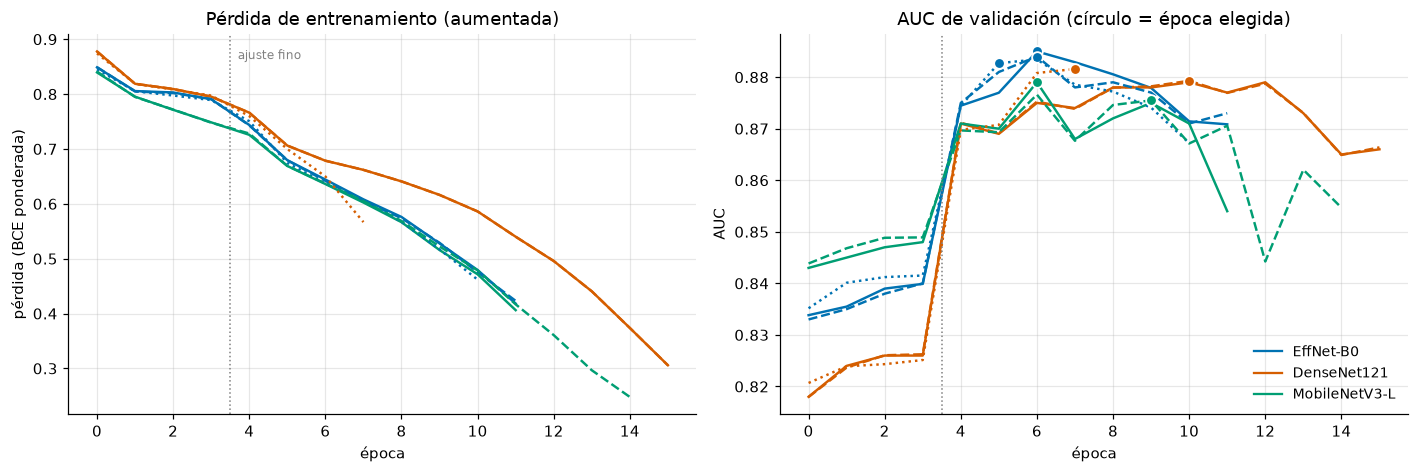

Pérdida de entrenamiento: primera -> última época, por corrida (todas bajan; no hay subajuste que explicar con ella):
  EffNet-B0 · Kaggle c2                  0.849 -> 0.418
  DenseNet121 · Kaggle c1                0.878 -> 0.306
  DenseNet121 · Kaggle c2                0.878 -> 0.306
  EffNet-B0 · Kaggle c1                  0.849 -> 0.423
  MobileNetV3-L · Kaggle c1              0.840 -> 0.406
  EffNet-B0 · corrida 6 (desplegada)     0.845 -> 0.462
  MobileNetV3-L · Kaggle c2              0.841 -> 0.248
  DenseNet121 · Colab 4+4                0.874 -> 0.567


In [13]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.4), sharex=True)
estilos = {}
for _, fila in tabla.iterrows():
    arq, color = fila["arq"], ARQUITECTURAS[fila["arq"]][1]
    repeticion = estilos.setdefault(arq, [])
    repeticion.append(fila["nombre"])
    estilo = ["-", "--", ":", "-."][(len(repeticion) - 1) % 4]
    h = reportes[fila["nombre"]]["historial"]
    ep = [e["epoca"] for e in h]
    izq.plot(ep, [e["perdida"] for e in h], estilo, color=color, lw=1.6)
    der.plot(ep, [e["auc"] for e in h], estilo, color=color, lw=1.6)
    der.plot([fila["mejor época"]], [en_epoca(reportes[fila["nombre"]], fila["mejor época"])["auc"]], "o", color=color,
             ms=7, mec="white", mew=1.2)
for eje in (izq, der):
    eje.axvline(3.5, color="gray", ls=":", lw=1)
izq.text(3.7, izq.get_ylim()[1] * 0.97, "ajuste fino", fontsize=8, color="gray", va="top")
izq.set(title="Pérdida de entrenamiento (aumentada)", xlabel="época", ylabel="pérdida (BCE ponderada)")
der.set(title="AUC de validación (círculo = época elegida)", xlabel="época", ylabel="AUC")
for arq, (nombre, color) in ARQUITECTURAS.items():
    der.plot([], [], "-", color=color, label=nombre)
der.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

print("Pérdida de entrenamiento: primera -> última época, por corrida (todas bajan; no hay subajuste que explicar con ella):")
for _, fila in tabla.iterrows():
    h = reportes[fila["nombre"]]["historial"]
    print(f"  {fila['corrida']:<38} {h[0]['perdida']:.3f} -> {h[-1]['perdida']:.3f}")

**Lectura.** En las ocho corridas la pérdida de entrenamiento baja sin parar hasta el final, y el AUC de validación sube de golpe al descongelar, toca techo (hacia la época 6 en EfficientNet-B0 y MobileNetV3-L, hacia la 10 en DenseNet121) y **retrocede después**. Es la firma del sobreajuste: el modelo sigue aprendiendo el conjunto de entrenamiento mientras deja de aprender lo que generaliza. La época elegida por la parada temprana cae en el techo o muy cerca. En la figura, el color es la arquitectura y los estilos de línea distintos son repeticiones; las dos de DenseNet121 coinciden.

### 5.2 Las tres corridas de la Semana 3: con la pérdida de validación

Las tres corridas de Kaggle del 26-sep-2026 (misma configuración y partición que el modelo desplegado, una por arquitectura) registran además la pérdida de validación y la de entrenamiento **limpia** (sin aumento, con el modelo quieto). Son las que se usaron en el diagnóstico de la Semana 3, y sus historiales por época se guardan en `notebooks/historiales_semana3.json`. Se diagnostican con `diagnosticar` de `scripts/diagnostico_curvas.py`, que fija sus umbrales por escrito (una subida de más del 5 % de la pérdida de validación desde su mínimo es sobreajuste, y no ruido).

La brecha se mide con la pérdida de **entrenamiento limpia** frente a la de validación, no con la aumentada: usar la aumentada subestima la brecha y en las primeras épocas puede invertirla, de modo que el sobreajuste parece subajuste.

In [14]:
filas = []
for c in corridas_s3:
    d = dx.diagnosticar(c["historial"])
    filas.append({"corrida": ARQUITECTURAS[c["corrida"]["arquitectura"]][0], "veredicto": d["veredicto"],
                  "épocas": d["epocas"], "mínimo de pérdida val. (época)": f"{d['perdida_val_minima']:.4f} ({d['epoca_minimo_val']})",
                  "pérdida val. final": round(d["perdida_val_final"], 4),
                  "subida desde el mínimo": f"{d['subida_desde_el_minimo']:+.1%}",
                  "memoriza desde la época": d["sobreajuste_desde_la_epoca"],
                  "AUC train / val final": f"{d['auc_train_final']:.4f} / {d['auc_val_final']:.4f}",
                  "brecha de pérdida (mín. -> final)": f"{d['brecha_perdida_minima']:.3f} -> {d['brecha_perdida_final']:.3f}",
                  "efecto del aumento": round(d["efecto_aumentacion"], 3)})
    h = c["historial"]
    brecha = lambda e: e["perdida_val"] - e["perdida_train"]
    filas[-1]["pérdida de entrenamiento final (limpia)"] = round(h[-1]["perdida_train"], 3)
    filas[-1]["crecimiento de la brecha desde la época 4"] = f"x{brecha(h[-1]) / brecha(next(e for e in h if e['epoca'] == 4)):.1f}"
print(pd.DataFrame(filas).T.to_string(header=False))

print("\nCriterios del diagnóstico (declarados en el script):",
      f"subida > {dx.SUBIDA_SOBREAJUSTE:.0%} o brecha de AUC > {dx.BRECHA_ALTA} = sobreajuste;",
      f"ambas pérdidas > {dx.PERDIDA_ALTA_AMBAS} = subajuste")

corrida                                        DenseNet121        EffNet-B0    MobileNetV3-L
veredicto                                      sobreajuste      sobreajuste      sobreajuste
épocas                                                  14               13               14
mínimo de pérdida val. (época)                  0.6937 (6)       0.6947 (7)       0.6999 (6)
pérdida val. final                                  0.8238            1.169           1.3666
subida desde el mínimo                              +18.7%           +68.3%           +95.3%
memoriza desde la época                                 10                8                7
AUC train / val final                      0.9762 / 0.8718  0.9910 / 0.8670  0.9918 / 0.8629
brecha de pérdida (mín. -> final)           0.083 -> 0.481   0.196 -> 0.969   0.135 -> 1.186
efecto del aumento                                   0.097            0.151            0.101
pérdida de entrenamiento final (limpia)              0.342            

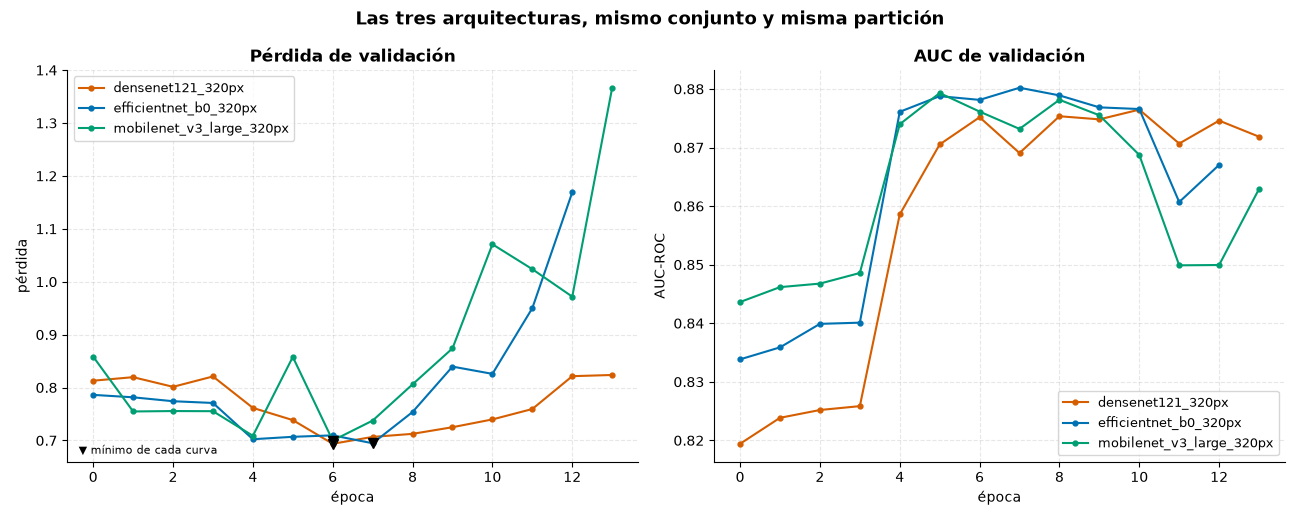

In [15]:
dx.DPI = 100  # las figuras del script salen a 300 DPI; aquí se bajan para que el cuaderno no pese
# el script dibuja con el ciclo de colores por defecto; se le pasa la paleta de arriba para que cada arquitectura conserve su color
ciclo = plt.cycler(color=[ARQUITECTURAS[c["corrida"]["arquitectura"]][1] for c in corridas_s3])
with tempfile.TemporaryDirectory() as temporal, plt.rc_context({"axes.prop_cycle": ciclo}):
    temporal = Path(temporal)
    comparativa = dx.figura_comparativa(corridas_s3, temporal / "comparativa.png")
    display(MostrarImagen(filename=str(comparativa)))

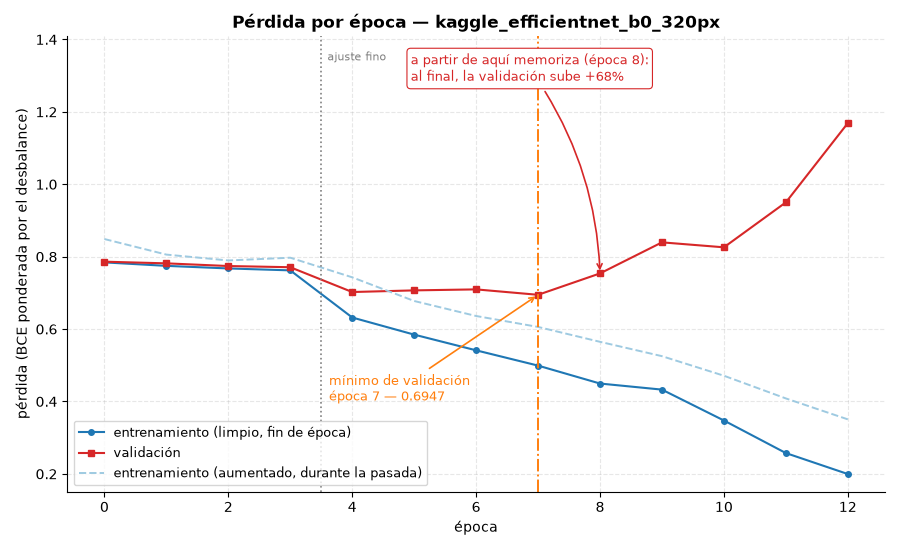

In [16]:
efficientnet_s3 = next(c for c in corridas_s3 if c["corrida"]["arquitectura"] == "efficientnet_b0")
with tempfile.TemporaryDirectory() as temporal:
    temporal = Path(temporal)
    display(MostrarImagen(filename=str(dx.figura_perdidas(efficientnet_s3, temporal / "perdidas.png"))))

**Diagnóstico.**

- **Sobreajuste en las tres arquitecturas**, sin ambigüedad en la dirección: la pérdida de validación toca fondo entre la época 6 y la 7 y después sube; la de entrenamiento limpia sigue bajando; el AUC de entrenamiento llega a 0,98-0,99 y el de validación se queda en 0,86-0,87; y la brecha de pérdida se multiplica por 10 o más desde el descongelado (época 4).
- **No es subajuste:** la pérdida de entrenamiento limpia baja a los valores de la tabla de arriba (entre 0,18 y 0,34) y el AUC de entrenamiento es casi perfecto: el modelo tiene capacidad de sobra.
- **No es un punto óptimo:** las curvas divergen en lugar de converger.
- **La aumentación no basta, pero se nota:** la pasada aumentada tiene una pérdida mayor que la limpia en la última época (fila «efecto del aumento»), y sin esa distinción las primeras épocas parecerían subajuste.
- **Una cautela de honestidad** (Semana 3): son tres corridas con una sola semilla; las diferencias **entre** arquitecturas (por ejemplo, cuánto crece la brecha) **no se pueden atribuir a la arquitectura** con confianza. Lo que las tres sostienen a la vez, y es el hallazgo, es **la dirección**.

### 5.3 Qué se hizo contra el sobreajuste, y cuánto compró

| Medida | Estado | Evidencia |
| :--- | :--- | :--- |
| Partición por paciente verificada sin fuga | aplicada | cuaderno 02, §7 |
| Aumento de datos solo en entrenamiento | aplicado | cuaderno 02, §8 |
| Parada temprana por recall con AUC de desempate, paciencia por fase, restauración de la mejor época | **aplicada** | abajo |
| Recocido coseno de la tasa | aplicado | §4 (efecto no aislado) |
| Paciencia 5 → 3 | **recomendada, no aplicada** a la corrida desplegada | §4.5 |
| Más dropout, otro decaimiento de pesos, otra aumentación, menos capacidad | **no probadas** | no se pueden evaluar sin reentrenar |

In [17]:
filas = []
for c in corridas_s3:
    h = c["historial"]
    sin_parada = h[-1]                                    # lo que se habría tenido parando al final de lo grabado
    elegida = next(e for e in h if e["epoca"] == dx.simular_parada(h, "recall+auc", 5)["epoca_elegida"])
    filas.append({"corrida": ARQUITECTURAS[c["corrida"]["arquitectura"]][0],
                  "sin parada: época, pérdida val., AUC val.": f"{sin_parada['epoca']}, {sin_parada['perdida_val']:.4f}, {sin_parada['auc']:.4f}",
                  "con parada: época, pérdida val., AUC val.": f"{elegida['epoca']}, {elegida['perdida_val']:.4f}, {elegida['auc']:.4f}",
                  "pérdida val.": f"{elegida['perdida_val'] / sin_parada['perdida_val'] - 1:+.1%}",
                  "AUC val.": f"{elegida['auc'] - sin_parada['auc']:+.4f}"})
print("Antes / después de la parada temprana (las dos son épocas grabadas del mismo historial, no una simulación):")
print(pd.DataFrame(filas).to_string(index=False))
print("\nEl «antes» se queda corto: sin parada el bucle habría seguido hasta la época 23, y esas épocas no están grabadas.")

Antes / después de la parada temprana (las dos son épocas grabadas del mismo historial, no una simulación):
      corrida sin parada: época, pérdida val., AUC val. con parada: época, pérdida val., AUC val. pérdida val. AUC val.
  DenseNet121                        13, 0.8238, 0.8718                         8, 0.7125, 0.8753       -13.5%  +0.0035
    EffNet-B0                        12, 1.1690, 0.8670                         7, 0.6947, 0.8802       -40.6%  +0.0132
MobileNetV3-L                        13, 1.3666, 0.8629                         8, 0.8061, 0.8781       -41.0%  +0.0152

El «antes» se queda corto: sin parada el bucle habría seguido hasta la época 23, y esas épocas no están grabadas.


## 6. Calibración

La salida cruda de la red **no es una probabilidad**. El modelo se entrenó con `BCEWithLogitsLoss(pos_weight ≈ 3,5)` para compensar que solo el 22 % de las placas son positivas, lo que empuja su salida hacia arriba: un 0,74 no significa un 74 % de probabilidad de neumonía. El sistema combina la evidencia de la imagen con la de la clínica **multiplicando razones de verosimilitud**; si la imagen entra sin calibrar, ese producto sale equivocado «sin que nada falle de forma visible».

Por eso se ajusta un **calibrador isotónico** (`ajustar_calibrador`) sobre la **validación**, nunca sobre la prueba. Es isotónico y no Platt porque no impone forma sigmoide: solo exige que la probabilidad no baje cuando sube la puntuación. Se guarda como una lista de puntos (`servidor/calibrador.json`), no como un objeto de scikit-learn. La razón de verosimilitud sale de la probabilidad calibrada y está **acotada por lo que la curva sostiene**: ninguna radiografía justifica más certeza que la que las 3 810 de validación respaldan.

Para volver a ver todo esto hay que **recalcular las puntuaciones de validación** con los pesos desplegados. Primero se localizan los pesos y se comprueba su SHA-256 contra el que declara `app/assets/metricas.json`.

In [18]:
def sha256_de(ruta):
    h = hashlib.sha256()
    with Path(ruta).open("rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


candidatos = [RAIZ / "corridas" / DESPLEGADA / "checkpoints" / "pesos_modelo_cpu.pt",
              REPO / "servidor" / "pesos_modelo_cpu.pt", REPO / "models" / "pesos_modelo_cpu.pt"]
PESOS = next((p for p in candidatos if p.is_file()), None)
assert PESOS is not None, "no están los pesos del modelo desplegado (ver models/README.md)"
assert sha256_de(PESOS) == METRICAS["pesos_sha256"], "los pesos no son los del modelo desplegado"
print("pesos localizados; SHA-256 =", METRICAS["pesos_sha256"], "(coincide con app/assets/metricas.json)")

pesos localizados; SHA-256 = bb985e1f792e1cfee150ec57bdc6d706f7484499fa999da3406a5798260e8d47 (coincide con app/assets/metricas.json)


In [19]:
from torch.utils.data import DataLoader

from copiloto_triaje.datos.dataset import DatasetRadiografias
from copiloto_triaje.modelo.arquitectura import construir_modelo

torch.manual_seed(cfg.semilla)
modelo = construir_modelo("efficientnet_b0", congelar_backbone=False, preentrenado=False)
modelo.load_state_dict(torch.load(PESOS, map_location="cpu", weights_only=True))
modelo.eval()

val = pd.read_csv(RAIZ / "manifiestos" / "val.csv")
cargador = DataLoader(DatasetRadiografias(val, RAIZ / "png", cfg.tam_imagen, entrenamiento=False),
                      batch_size=32, num_workers=0)
y_val, s_val = [], []
with torch.no_grad():
    for x, etiquetas in cargador:
        s_val.extend(torch.sigmoid(modelo(x).view(-1)).tolist())
        y_val.extend(etiquetas.tolist())
y_val, s_val = np.asarray(y_val).astype(int), np.asarray(s_val)
vista_val = val["vista"].to_numpy()
print(f"{len(y_val):,} radiografías de validación puntuadas ({int(y_val.sum())} con opacidad)")
print(f"AUC de validación: {roc_auc_score(y_val, s_val):.4f}  (docs/frontera-recall-especificidad.md dice 0,8827)")

3,810 radiografías de validación puntuadas (844 con opacidad)
AUC de validación: 0.8827  (docs/frontera-recall-especificidad.md dice 0,8827)


In [20]:
from copiloto_triaje.servicio.calibracion import Calibrador, ajustar_calibrador
from copiloto_triaje.validacion import metricas as vm

desplegado = Calibrador.desde_json(REPO / "servidor" / "calibrador.json")
reajustado = ajustar_calibrador(y_val, s_val, desplegado.prevalencia, "reajustado en el cuaderno 04")

malla = np.linspace(0.0, 1.0, 2001)
diferencia = np.abs(np.interp(malla, reajustado.x, reajustado.y) - np.interp(malla, desplegado.x, desplegado.y))
print(f"prevalencia del calibrador desplegado: {desplegado.prevalencia} | puntos de la curva: {len(desplegado.x)}")
print(f"curva isotónica REAJUSTADA aquí frente a la desplegada: diferencia máxima {diferencia.max():.2e}, media {diferencia.mean():.2e}")

lo, hi = desplegado.probabilidad_minima_sostenida, desplegado.probabilidad_maxima_sostenida
print(f"probabilidad calibrada acotada a [{lo:.4f}, {hi:.4f}] -> razón de verosimilitud en "
      f"[{desplegado.razon_de_verosimilitud(0.0):.3g}, {desplegado.razon_de_verosimilitud(1.0):.3g}]")

# Fiabilidad de la salida CRUDA en validación (diez tramos de igual masa, la ECE del proyecto)
orden = np.arange(len(y_val))
fiab_cruda = vm.fiabilidad(y_val, s_val, orden)
print(f"\nSalida cruda, en validación: ECE {vm.ece(y_val, s_val, orden):.3f}, Brier {vm.brier(y_val, s_val):.3f}, "
      f"pendiente de calibración {vm.pendiente_de_calibracion(y_val, s_val):.2f}, "
      f"intercepto {vm.intercepto_de_calibracion(y_val, s_val):+.2f}")
print("(pendiente 1 e intercepto 0 serían una calibración perfecta; la ECE se lee al lado de su suelo de ruido, ver el cuaderno 05)")

prevalencia del calibrador desplegado: 0.2215 | puntos de la curva: 200
curva isotónica REAJUSTADA aquí frente a la desplegada: diferencia máxima 1.06e-05, media 5.59e-08
probabilidad calibrada acotada a [0.0046, 0.9565] -> razón de verosimilitud en [0.0163, 77.3]

Salida cruda, en validación: ECE 0.172, Brier 0.153, pendiente de calibración 0.90, intercepto -1.48
(pendiente 1 e intercepto 0 serían una calibración perfecta; la ECE se lee al lado de su suelo de ruido, ver el cuaderno 05)


Imagen sola, CALIBRADA, sobre la PRUEBA (de resultados_simulacion.json):
  AUC 0.884 | Brier 0.108 | pendiente 0.98 | intercepto +0.012 | ECE 0.0163 (suelo de ruido: media 0.0116, p95 0.0174)


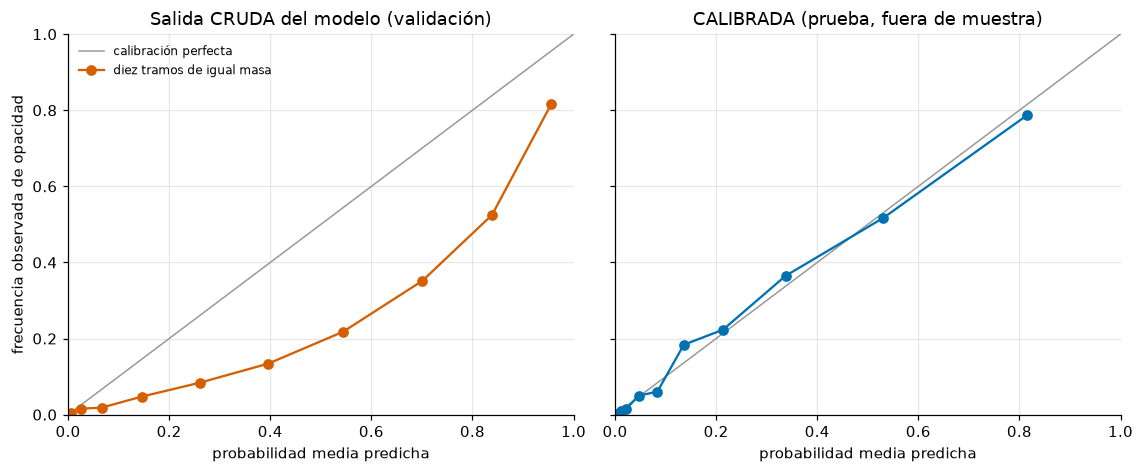

In [21]:
sim = json.loads((REPO / "docs" / "validacion-semisintetica" / "resultados_simulacion.json").read_text(encoding="utf-8"))
sola = sim["imagen_sola"]   # la imagen calibrada sobre las 3 811 placas de PRUEBA (fuera de muestra)
print("Imagen sola, CALIBRADA, sobre la PRUEBA (de resultados_simulacion.json):")
print(f"  AUC {sola['auc']:.3f} | Brier {sola['brier']:.3f} | pendiente {sola['pendiente']:.2f} | intercepto {sola['intercepto']:+.3f} | "
      f"ECE {sola['ece']:.4f} (suelo de ruido: media {sola['suelo']['media']:.4f}, p95 {sola['suelo']['p95']:.4f})")

fig, ejes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharex=True, sharey=True)
for eje, puntos, titulo, color in (
        (ejes[0], fiab_cruda, "Salida CRUDA del modelo (validación)", "#D55E00"),
        (ejes[1], sola["fiabilidad"], "CALIBRADA (prueba, fuera de muestra)", "#0072B2")):
    p = [f["p_media"] for f in puntos]
    o = [f["observada"] for f in puntos]
    eje.plot([0, 1], [0, 1], color="#999999", lw=1, label="calibración perfecta")
    eje.plot(p, o, "o-", color=color, ms=6, label="diez tramos de igual masa")
    eje.set(title=titulo, xlabel="probabilidad media predicha", xlim=(0, 1), ylim=(0, 1))
ejes[0].set_ylabel("frecuencia observada de opacidad")
ejes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

**Lectura.**

- **Sin calibrar, la salida del modelo exagera** (ECE 0,17, pendiente 0,90, intercepto −1,48 en validación): en los tramos bajos y medios predice una probabilidad mucho mayor que la frecuencia observada de opacidad (la curva naranja queda **por debajo** de la diagonal), como era de esperar con `pos_weight`. Es la razón de existir del calibrador.
- **Calibrada, y fuera de muestra, queda sobre la diagonal:** pendiente 0,98, intercepto 0,01, ECE 0,016 con un suelo de ruido de 0,012 (percentil 95 de 0,017): **no se distingue del ruido de muestreo**. El calibrador se ajustó solo con validación y aquí se mide sobre la prueba.
- **El calibrador desplegado es reproducible:** reajustar la isotónica sobre las puntuaciones de validación recalculadas da la misma curva que la desplegada (diferencia máxima de unas 10⁻⁵ en probabilidad, ruido numérico de la CPU).
- **Qué no dice esto:** que esté calibrado **en otra población**. La prevalencia del calibrador es la del conjunto (0,2215), no la de un servicio real; el sistema desplegado arranca con una prevalencia local declarada (0,1466) que desplaza las probabilidades (cuaderno 05).

## 7. La elección del umbral de cribado

El modelo entrega una puntuación continua; el cribado necesita un corte. `elegir_umbral` lo elige sobre la **curva ROC de validación** (nunca la de prueba) con una regla que ordena los puntos de operación por cuánto del spec satisfacen y, ante empate, prefiere el de mayor especificidad: recall objetivo con especificidad objetivo; recall objetivo con la especificidad mínima; recall mínimo con la especificidad objetivo; recall mínimo con la especificidad mínima; y, si ninguno alcanza el recall mínimo, el de mayor recall dentro del piso de especificidad, **sin forzar nada**.

In [22]:
from copiloto_triaje.modelo.evaluacion import elegir_umbral

umbral, m_val, paso_umbral = elegir_umbral(y_val, s_val, cfg.especificidad_objetivo, cfg.especificidad_minima,
                                           cfg.recall_objetivo, cfg.recall_minimo, margen_especificidad=0.0)
print(f"umbral elegido en validación: {umbral:.4f} ({paso_umbral})")
print(f"  validación: recall {m_val['recall']:.4f}, especificidad {m_val['especificidad']:.4f}, AUC {m_val['auc']:.4f}")
print(f"  el que sirve el motor (app/assets/metricas.json): {METRICAS['umbral']}  ->  "
      f"coincide: {round(umbral, 4) == METRICAS['umbral']}")
print(f"  prueba, con ese umbral: recall {g['recall']:.4f}, especificidad {g['especificidad']:.4f}  "
      f"(la validación predijo bien el punto de operación)")

# La frontera: para cada piso de especificidad, el mayor recall alcanzable (misma lógica que `mejor_indice` de elegir_umbral)
fpr, tpr, umbrales = roc_curve(y_val, s_val)
espec = 1.0 - fpr
filas = []
for piso in (0.70, 0.72, 0.75, 0.78, 0.80, 0.85):
    candidatos = np.where(espec >= piso)[0]
    i = int(candidatos[np.argmax(tpr[candidatos])])
    filas.append({"especificidad exigida": piso, "especificidad real": round(espec[i], 4),
                  "recall": round(tpr[i], 4), "umbral": round(float(umbrales[i]), 4)})
print("\nLa frontera recall / especificidad en VALIDACIÓN (3 810 radiografías):")
print(pd.DataFrame(filas).to_string(index=False))

alcanzable = bool(np.any((tpr >= cfg.recall_objetivo) & (espec >= cfg.especificidad_objetivo)))
con_piso = espec >= cfg.especificidad_objetivo
print(f"\n¿Hay algún punto con recall >= {cfg.recall_objetivo} y especificidad >= {cfg.especificidad_objetivo} a la vez? {alcanzable}")
print(f"El mejor recall con especificidad >= {cfg.especificidad_objetivo}: {tpr[con_piso].max():.4f}")

# Sensibilidad de la ELECCIÓN al margen de especificidad (Config.margen_especificidad, 0,02 en el entrenamiento nuevo)
for margen in (0.0, 0.02):
    u, m, p = elegir_umbral(y_val, s_val, cfg.especificidad_objetivo, cfg.especificidad_minima,
                            cfg.recall_objetivo, cfg.recall_minimo, margen_especificidad=margen)
    print(f"margen {margen:.2f}: umbral {u:.4f}, recall {m['recall']:.4f}, especificidad {m['especificidad']:.4f} ({p})")

umbral elegido en validación: 0.4258 (paso_2_especificidad_minima)
  validación: recall 0.8815, especificidad 0.7006, AUC 0.8827
  el que sirve el motor (app/assets/metricas.json): 0.4258  ->  coincide: True
  prueba, con ese umbral: recall 0.8815, especificidad 0.7024  (la validación predijo bien el punto de operación)

La frontera recall / especificidad en VALIDACIÓN (3 810 radiografías):
 especificidad exigida  especificidad real  recall  umbral
                  0.70              0.7006  0.8815  0.4258
                  0.72              0.7256  0.8637  0.4649
                  0.75              0.7522  0.8400  0.5029
                  0.78              0.7815  0.8187  0.5407
                  0.80              0.8007  0.8033  0.5655
                  0.85              0.8506  0.7358  0.6575

¿Hay algún punto con recall >= 0.85 y especificidad >= 0.75 a la vez? False
El mejor recall con especificidad >= 0.75: 0.8400
margen 0.00: umbral 0.4258, recall 0.8815, especificidad 0.7006 (p

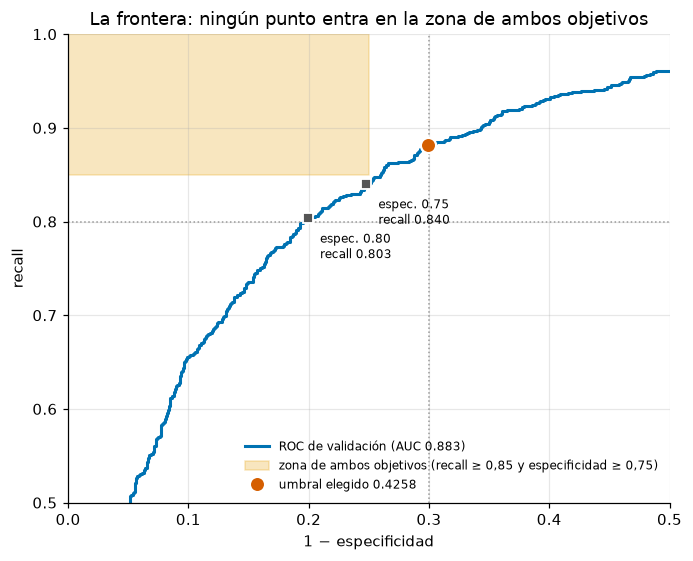

In [23]:
fig, eje = plt.subplots(figsize=(6.4, 5.2))
eje.plot(fpr, tpr, color="#0072B2", lw=2, label=f"ROC de validación (AUC {roc_auc_score(y_val, s_val):.3f})")
eje.fill_between([0, 1 - cfg.especificidad_objetivo], cfg.recall_objetivo, 1, color="#E69F00", alpha=0.25,
                 label="zona de ambos objetivos (recall ≥ 0,85 y especificidad ≥ 0,75)")
eje.axhline(cfg.recall_minimo, color="#999999", ls=":", lw=1)
eje.axvline(1 - cfg.especificidad_minima, color="#999999", ls=":", lw=1)
eje.plot(1 - m_val["especificidad"], m_val["recall"], "o", color="#D55E00", ms=10, mec="white", mew=1.5,
         label=f"umbral elegido {umbral:.4f}")
for fila in filas:
    if fila["especificidad exigida"] in (0.75, 0.80):
        eje.plot(1 - fila["especificidad real"], fila["recall"], "s", color="#555555", ms=7, mec="white", mew=1.2)
        eje.annotate(f"espec. {fila['especificidad exigida']:.2f}\nrecall {fila['recall']:.3f}",
                     (1 - fila["especificidad real"], fila["recall"]), xytext=(8, -26), textcoords="offset points", fontsize=8)
eje.set(xlim=(0, 0.5), ylim=(0.5, 1.0), xlabel="1 − especificidad", ylabel="recall",
        title="La frontera: ningún punto entra en la zona de ambos objetivos")
eje.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

**Lectura.**

- **El umbral se reproduce:** `elegir_umbral` sobre las puntuaciones recalculadas devuelve el mismo punto que sirve el motor (0,4258), con recall y especificidad de validación casi idénticos a los de prueba: la elección sobre validación **se transfiere**.
- **Los mínimos se cumplen con holgura; los dos objetivos a la vez, no.** No existe en validación ningún punto con recall ≥ 0,85 y especificidad ≥ 0,75: el mejor recall con especificidad ≥ 0,75 es 0,84. El documento maestro de la Semana 1 prometía «recall ≥ 85 % y especificidad ≥ 75 %»; este modelo no puede darlo (`docs/frontera-recall-especificidad.md` lo corrige). La distancia es corta: unas cinco milésimas de AUC.
- **No se reentrenó persiguiendo el listón:** elegir la corrida que casualmente lo cruza es seleccionar por ruido. Lo honesto es **publicar la frontera, no un punto**, y decir qué falta para moverla (más datos, más resolución o un backbone mejor).
- **Por qué el punto por defecto prioriza el recall:** un falso negativo manda a casa una neumonía; un falso positivo cuesta una radiografía revisada de más.
- **El margen de especificidad** (`margen_especificidad`) sube los suelos al elegir, para que el punto no quede rozando el mínimo: cambia el umbral y cuesta unas milésimas de recall. Se introdujo después de que una corrida de DenseNet121 cayera trece diezmilésimas por debajo del mínimo en prueba. El umbral desplegado se reproduce con margen 0 y no con 0,02 (que daría 0,4649), así que la corrida desplegada lo usó en 0.

## 8. El umbral por vista

La vista (PA, de pie; AP, portátil) **predice la etiqueta** (cuaderno 02, §7): con **un único umbral** el modelo se comporta de forma muy distinta en cada vista. La mitigación evaluada, **apagada por defecto**, es un umbral por vista, elegido en validación para **igualar el recall de las dos vistas al del punto de operación global** (igualdad de oportunidad) y evaluado en prueba, que no se mira al elegir.

La regla vive en el taller de la Semana 4 (no en el paquete: el motor solo recibe los dos umbrales), así que aquí se reimplementa en tres líneas: en cada vista, el **umbral más alto** cuyo recall en validación alcanza el recall global.

In [24]:
def umbral_para_recall(y, p, objetivo):
    # El umbral MÁS ALTO cuyo recall en estos datos es >= objetivo (regla del workshop S4, tabla 3).
    positivas = np.sort(p[y == 1])[::-1]
    k = int(np.ceil(objetivo * len(positivas)))
    return float(positivas[k - 1])


recall_global_val = float(((s_val >= METRICAS["umbral"]) & (y_val == 1)).sum() / (y_val == 1).sum())
print(f"recall global de validación con el umbral {METRICAS['umbral']}: {recall_global_val:.4f}")
por_vista = {}
for vista in ("PA", "AP"):
    dentro = vista_val == vista
    por_vista[vista] = umbral_para_recall(y_val[dentro], s_val[dentro], recall_global_val)
    m = (y_val[dentro] == 1)
    esp = float(((s_val[dentro] < por_vista[vista]) & (y_val[dentro] == 0)).sum() / (y_val[dentro] == 0).sum())
    print(f"  vista {vista}: n = {dentro.sum():,}, positivas = {int(m.sum())} -> umbral {por_vista[vista]:.4f}, "
          f"especificidad en validación {esp:.3f}")
print("los de app/assets/metricas.json:", METRICAS["umbrales_por_vista"],
      "| coinciden:", {v: round(por_vista[v], 4) == METRICAS["umbrales_por_vista"][v] for v in por_vista})

recall global de validación con el umbral 0.4258: 0.8815
  vista PA: n = 2,118, positivas = 181 -> umbral 0.1798, especificidad en validación 0.631
  vista AP: n = 1,692, positivas = 663 -> umbral 0.5815, especificidad en validación 0.548
los de app/assets/metricas.json: {'PA': 0.1798, 'AP': 0.5815} | coinciden: {'PA': True, 'AP': True}


Efecto en PRUEBA (intervalos de Wilson, de app/assets/metricas.json):
 grupo         umbrales    n    recall (IC 95 %) especificidad (IC 95 %)
    PA        un umbral 2087 0.693 (0.626-0.753)     0.880 (0.865-0.894)
    PA umbral por vista 2087 0.891 (0.841-0.927)     0.646 (0.624-0.667)
    AP        un umbral 1724 0.941 (0.920-0.957)     0.393 (0.364-0.422)
    AP umbral por vista 1724 0.888 (0.861-0.910)     0.561 (0.531-0.590)
global        un umbral 3811 0.882 (0.858-0.902)     0.702 (0.686-0.719)
global umbral por vista 3811 0.889 (0.866-0.908)     0.615 (0.597-0.632)


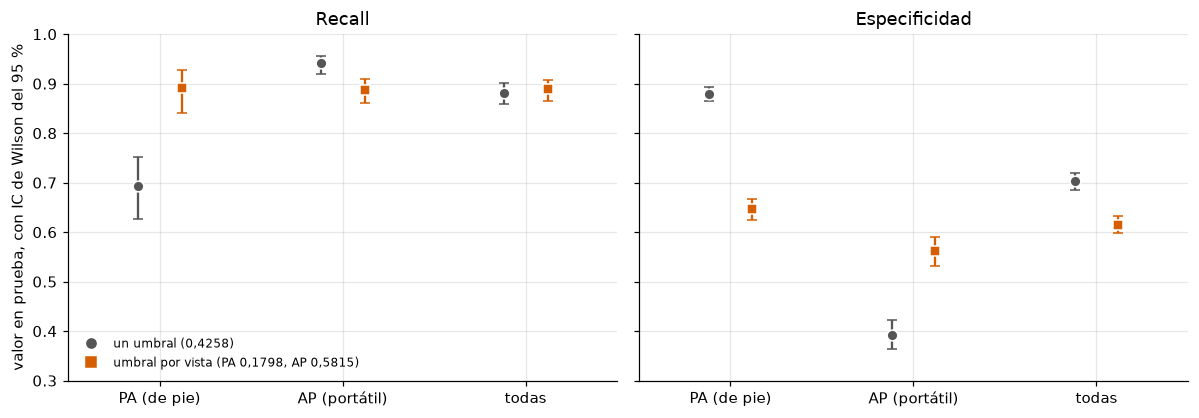

In [25]:
efecto = METRICAS["umbral_por_vista_en_prueba"]
filas = []
for grupo in ("PA", "AP", "global"):
    for clave, texto in (("un_umbral", "un umbral"), ("dos_umbrales", "umbral por vista")):
        e = efecto[clave][grupo]
        filas.append({"grupo": grupo, "umbrales": texto, "n": e["n"],
                      "recall (IC 95 %)": f"{e['recall']:.3f} ({e['recall_ic'][0]:.3f}-{e['recall_ic'][1]:.3f})",
                      "especificidad (IC 95 %)": f"{e['especificidad']:.3f} ({e['especificidad_ic'][0]:.3f}-{e['especificidad_ic'][1]:.3f})"})
print("Efecto en PRUEBA (intervalos de Wilson, de app/assets/metricas.json):")
print(pd.DataFrame(filas).to_string(index=False))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for eje, metrica, titulo in zip(ejes, ("recall", "especificidad"), ("Recall", "Especificidad")):
    for x, grupo in enumerate(("PA", "AP", "global")):
        for desplazamiento, clave, color, marca in ((-0.12, "un_umbral", "#555555", "o"), (0.12, "dos_umbrales", "#D55E00", "s")):
            e = efecto[clave][grupo]
            ic = e[f"{metrica}_ic"]
            eje.errorbar(x + desplazamiento, e[metrica], yerr=[[e[metrica] - ic[0]], [ic[1] - e[metrica]]],
                         fmt=marca, color=color, ms=7, capsize=3, mec="white", mew=1)
    eje.set_xticks(range(3), ["PA (de pie)", "AP (portátil)", "todas"])
    eje.set(title=titulo, ylim=(0.3, 1.0), xlim=(-0.5, 2.5))
ejes[0].set_ylabel("valor en prueba, con IC de Wilson del 95 %")
ejes[0].plot([], [], "o", color="#555555", label="un umbral (0,4258)")
ejes[0].plot([], [], "s", color="#D55E00", label="umbral por vista (PA 0,1798, AP 0,5815)")
ejes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

**Lectura.**

- **Con un umbral, el sesgo de la vista es grande:** en PA el modelo deja pasar a casi un tercio de las opacidades (recall 0,69) y casi no da falsas alarmas (especificidad 0,88); en AP detecta casi todo (recall 0,94) a costa de marcar a más de la mitad de las placas sin opacidad (especificidad 0,39).
- **Con un umbral por vista, el recall se iguala** (0,89 en las dos vistas) **y la especificidad se reparte** (0,65 en PA y 0,56 en AP).
- **El precio:** la especificidad global baja de 0,70 a 0,62, bajo el mínimo del spec de 0,70, y el recall global sube de 0,88 a 0,89. Por eso no se activa por defecto: **se mueve el problema de sitio, no desaparece**, y hace falta que el equipo decida si prefiere igualar la sensibilidad entre vistas o mantener la especificidad global. La causa de fondo, que la vista predice la etiqueta en el conjunto de datos, no se arregla con un umbral.

## 9. La configuración final, antes y después

| Decisión | Antes | Final | Evidencia | Reservas |
| :--- | :--- | :--- | :--- | :--- |
| Arquitectura | MobileNetV3-Large | **EfficientNet-B0** | §3, §4.3: no peor que DenseNet121 y unas tres veces más rápida de entrenar (más lenta que MobileNetV3-L por poco: 0,5 h frente a 0,3-0,4 h) | la diferencia con las otras es del orden del ruido |
| Resolución | 224 px | **320 px** | `docs/mejoras-2026-09-21.md` §4 | no aislado: se cambió junto con otros siete |
| Épocas | 3 + 7 | **4 + 20 con parada temprana** | §4.4: el tope nunca ata | solo un contraste 4+4/4+20, sin repeticiones |
| Ajuste fino | 3 últimos bloques | **red completa** | §4.4: el salto al descongelar es el mayor efecto observado | no aislado de la tasa de aprendizaje |
| Parada | paciencia 3 | **paciencia 5 por fase; la época elegida por recall con AUC de desempate** | §4.5, §5.3 | se recomienda bajar a 3 (mismo resultado, menos épocas) |
| Calibración | salida cruda | **isotónica sobre validación**, RV acotada | §6: ECE 0,016 en prueba, sin distinguirse del ruido | solo vale para la población de RSNA |
| Umbral | regla original (conservaba un punto bajo el mínimo) | **0,4258**, elegido por `elegir_umbral` en validación | §7: se reproduce y se transfiere a prueba | los dos objetivos a la vez son inalcanzables |
| Umbral por vista | un único umbral | **evaluado, apagado por defecto** | §8 | iguala el recall y baja la especificidad global bajo el mínimo |

**Resultado final** (prueba, 3 811 placas; cuaderno 05): AUC 0,885, recall 0,882 y especificidad 0,702: cumple los tres mínimos y dos de los tres objetivos (recall y AUC); el objetivo de especificidad (0,75) no se alcanza.

**Lo que queda sin hacer, a la vista:** un barrido real de hiperparámetros (§4.6), repeticiones con semillas distintas, probar más regularización (dropout, decaimiento de pesos), y validar en una población distinta de RSNA.